In [ ]:
#import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [ ]:
#load dataset
df=pd.read_csv('/content/penguins_size.csv')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   culmen_length_mm   342 non-null    float64
 3   culmen_depth_mm    342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [ ]:
df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [ ]:
# Drop unnecessary columns
df.drop(columns=['island', 'sex'], inplace=True)

# Verify updated columns and shape
df.head()

,species,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
0,Adelie,39.1,18.7,181.0,3750.0
1,Adelie,39.5,17.4,186.0,3800.0
2,Adelie,40.3,18.0,195.0,3250.0
3,Adelie,NaN,NaN,NaN,NaN
4,Adelie,36.7,19.3,193.0,3450.0


In [ ]:
df.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


In [ ]:
df.shape

(344, 5)

In [ ]:
df.isnull().sum()

,0
species,0
culmen_length_mm,2
culmen_depth_mm,2
flipper_length_mm,2
body_mass_g,2


In [ ]:
# Drop rows with missing values
df.dropna(inplace=True)
df.isnull().sum()

,0
species,0
culmen_length_mm,0
culmen_depth_mm,0
flipper_length_mm,0
body_mass_g,0


In [ ]:
print("no of duplicated records: ",df.duplicated().sum())

no of duplicated records:  0


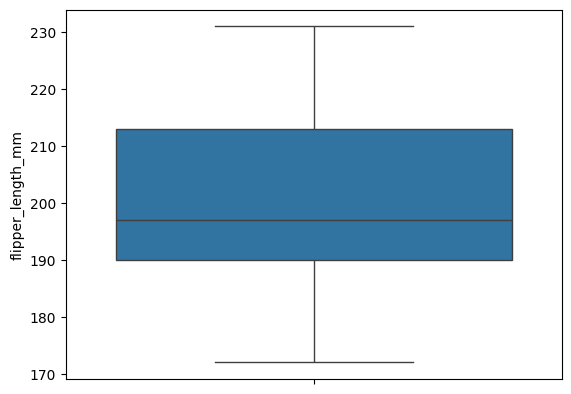

In [ ]:
sns.boxplot(df['flipper_length_mm'])
plt.show()

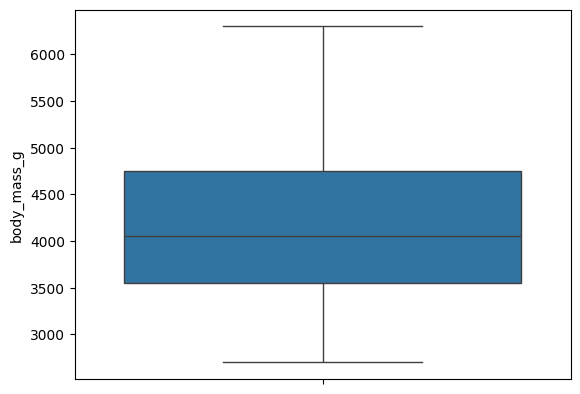

In [ ]:
sns.boxplot(df['body_mass_g'])
plt.show()

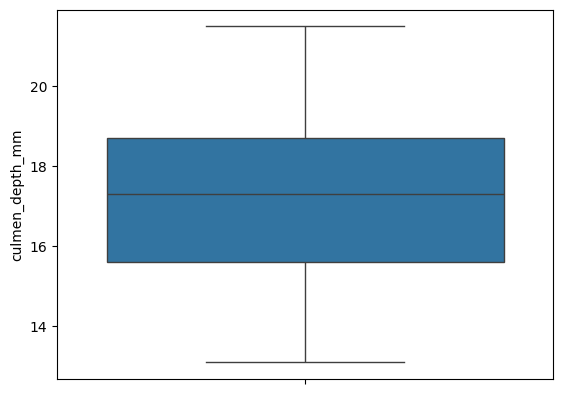

In [ ]:
sns.boxplot(df['culmen_depth_mm'])
plt.show()

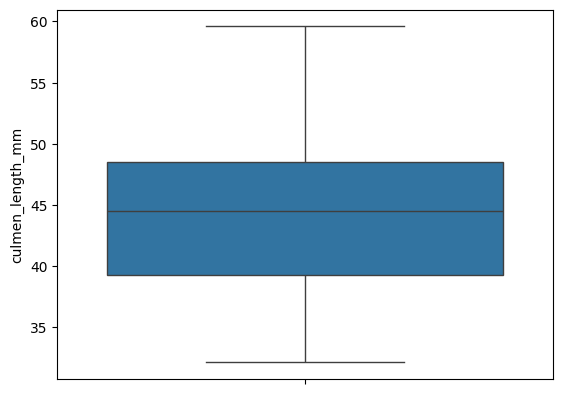

In [ ]:
sns.boxplot(df['culmen_length_mm'])
plt.show()

In [ ]:
#label encoding for target
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df['species']=le.fit_transform(df['species'])
df.head()

,species,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
0,0,39.1,18.7,181.0,3750.0
1,0,39.5,17.4,186.0,3800.0
2,0,40.3,18.0,195.0,3250.0
4,0,36.7,19.3,193.0,3450.0
5,0,39.3,20.6,190.0,3650.0


In [ ]:
# Separate features (X) and target variable (y)
x = df.drop(columns=['species'])
y = df['species']

In [ ]:
#split the data into training and testing
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.20,random_state=15)

In [ ]:
#satndardization
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
x_train=sc.fit_transform(x_train)
x_test=sc.transform(x_test)

In [ ]:
#model building
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train,y_train)

KNeighborsClassifier()

In [ ]:
#predictions on test data
y_pred=knn.predict(x_test)

In [ ]:
#evaluation metrics
accuracy_score(y_test,y_pred)
classification_report(y_test,y_pred)
confusion_matrix(y_test,y_pred)

array([[26,  0,  0],
       [ 0, 13,  0],
       [ 0,  0, 30]])

<Axes: >

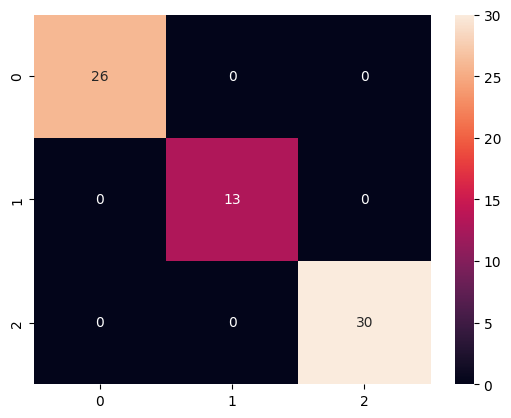

In [ ]:
#confusion matrix
sns.heatmap(confusion_matrix(y_test,y_pred),annot=True)

In [ ]:
from sklearn.metrics import accuracy_score, roc_auc_score
y_pred = knn.predict(x_test)
y_proba = knn.predict_proba(x_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
roc_auc = roc_auc_score(
y_test,
y_proba,
multi_class='ovr'
)
print("ROC-AUC Score:", roc_auc)

Accuracy: 1.0
ROC-AUC Score: 1.0


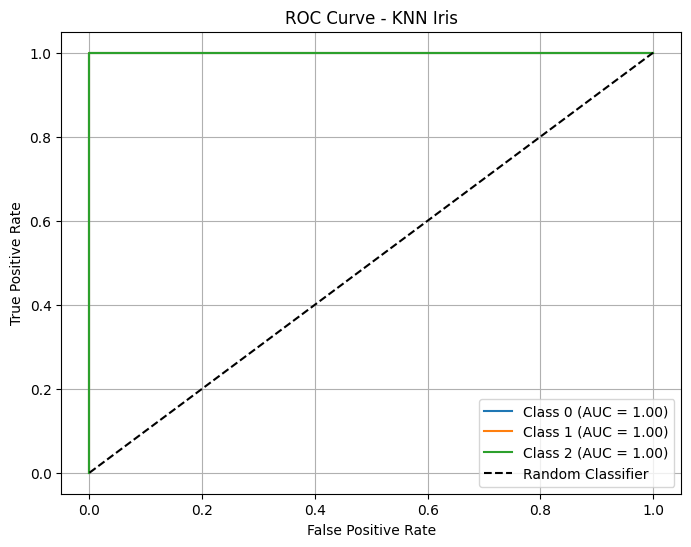

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
# Predict probabilities
y_proba = knn.predict_proba(x_test)
# Convert test labels into binary form
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
# Plot ROC curve for each class
plt.figure(figsize=(8, 6))
for i in range(3):
  fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
  auc_score = roc_auc_score(y_test_bin[:, i], y_proba[:, i])
  plt.plot(
    fpr, tpr,
    label=f'Class {i} (AUC = {auc_score:.2f})'
  )
# Random classifier
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - KNN Iris')
plt.legend()
plt.grid()
plt.show()

In [ ]:
overall_auc = roc_auc_score(
y_test_bin,
y_proba,
multi_class='ovr'
)
print("Overall ROC-AUC:", overall_auc)

Overall ROC-AUC: 1.0
